In [1]:
import pandas as pd

In [ ]:
##------------------------CTG DESCRIPTION
#LB : beats per second
#AC : acceleration per second
#FM : fetal movement per second
#NSP (Normal , suspect, pathalogical)

# CTG

In [4]:
pd.read_csv(r"C:\MLA\CTG.csv")

,LB,AC,FM,NSP
0,120,0.000,0.000,2
1,132,0.006,0.000,1
2,133,0.003,0.000,1
3,134,0.003,0.000,1
4,132,0.007,0.000,1
...,...,...,...,...
2121,140,0.000,0.000,2
2122,140,0.001,0.000,2
2123,140,0.001,0.000,2
2124,140,0.001,0.000,2


In [5]:
ctg=pd.read_csv(r"C:\MLA\CTG.csv")

In [6]:
ctg.isnull().sum()[ctg.isnull().sum()>0]

Series([], dtype: int64)

In [7]:
ctg.info()

<class 'pandas.DataFrame'>
RangeIndex: 2126 entries, 0 to 2125
Data columns (total 4 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   LB      2126 non-null   int64  
 1   AC      2126 non-null   float64
 2   FM      2126 non-null   float64
 3   NSP     2126 non-null   int64  
dtypes: float64(2), int64(2)
memory usage: 66.6 KB


In [8]:
from sklearn.model_selection import train_test_split
ctg_train,ctg_test=train_test_split(ctg,test_size=.2)

In [9]:
# over sampling
#df3=ctg_train[ctg_train.NSP==3]
#df2=ctg_train[ctg_train.NSP==2]

#ctg_train=pd.concat([ctg_train,df3,df3,df2,df2])
#ctg_train.shape

In [10]:
ctg.NSP.value_counts()

NSP
1    1655
2     295
3     176
Name: count, dtype: int64

In [11]:
ctg_train_x=ctg_train.iloc[:,0:-1]
ctg_train_y=ctg_train.iloc[:,-1]

ctg_test_x=ctg_test.iloc[:,0:-1]
ctg_test_y=ctg_test.iloc[:,-1]

In [12]:
from sklearn.tree import DecisionTreeClassifier
dt_ctg=DecisionTreeClassifier(class_weight='balanced')

In [13]:
dt_ctg.fit(ctg_train_x,ctg_train_y)

,"class_weight class_weight: dict, list of dict or ""balanced"", default=NoneWeights associated with classes in the form ``{class_label: weight}``.If None, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced'
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But

In [16]:
pred_test_ctg=dt_ctg.predict(ctg_test_x)
pred_test_ctg

array([1, 1, 3, 1, 1, 1, 1, 1, 2, 1, 1, 1, 1, 1, 3, 1, 1, 1, 2, 1, 1, 3,
       1, 1, 1, 2, 1, 1, 1, 2, 1, 1, 3, 1, 1, 1, 1, 2, 2, 1, 1, 1, 2, 1,
       2, 2, 3, 1, 1, 1, 2, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 2, 1, 1, 1,
       3, 1, 1, 2, 1, 1, 1, 3, 2, 2, 1, 1, 1, 2, 2, 2, 1, 2, 1, 2, 3, 1,
       1, 2, 2, 3, 3, 1, 1, 2, 1, 3, 2, 2, 1, 1, 1, 1, 1, 2, 1, 1, 1, 1,
       1, 1, 1, 1, 2, 2, 1, 2, 1, 1, 3, 2, 3, 2, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 2, 1, 1, 1, 1, 1, 1, 2, 3, 3, 1, 1, 1, 2, 1, 2, 2,
       2, 1, 1, 3, 3, 2, 1, 1, 3, 2, 1, 2, 1, 1, 2, 1, 1, 3, 1, 1, 2, 1,
       2, 2, 1, 1, 1, 2, 1, 1, 1, 2, 1, 1, 1, 2, 3, 1, 3, 3, 1, 1, 1, 1,
       2, 1, 1, 1, 2, 2, 3, 2, 1, 1, 3, 2, 3, 2, 3, 2, 1, 2, 1, 1, 1, 1,
       2, 1, 1, 1, 1, 1, 1, 1, 3, 1, 1, 1, 1, 2, 3, 2, 3, 1, 2, 2, 1, 1,
       1, 1, 1, 2, 1, 2, 2, 3, 1, 1, 1, 2, 1, 3, 1, 1, 1, 2, 1, 1, 1, 1,
       2, 2, 2, 1, 1, 1, 1, 1, 1, 1, 1, 2, 2, 1, 2, 3, 2, 2, 1, 2, 1, 1,
       3, 1, 1, 1, 2, 1, 1, 3, 1, 1, 1, 1, 1, 1, 3,

In [17]:
from sklearn.metrics import confusion_matrix,accuracy_score,precision_score,recall_score,f1_score

In [18]:
tab_ctg= confusion_matrix(ctg_test_y,pred_test_ctg)

In [ ]:
tab_ctg

array([[274,  43,  17],
       [  7,  44,  11],
       [  9,   0,  21]], dtype=int64)

In [19]:
accuracy_score(ctg_test_y,pred_test_ctg)

0.7816901408450704

In [20]:
precision_score(ctg_test_y,pred_test_ctg,average='macro')

0.6404199028747873

In [21]:
recall_score(ctg_test_y,pred_test_ctg,average='macro')

0.7463581250485424

In [22]:
f1_score(ctg_test_y,pred_test_ctg,average='macro')

0.6703994706555685

# Grid Search

In [23]:
from sklearn.model_selection import GridSearchCV

In [24]:
search_dict = {'criterion':['gini','entropy'],
              'max_depth':range(4,9),
              'min_samples_split':[50,75,100]}

In [25]:
dt_ctg=DecisionTreeClassifier()
grid=GridSearchCV(dt_ctg,param_grid=search_dict)

In [27]:
grid.fit(ctg_train_x,ctg_train_y)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",DecisionTreeClassifier()
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'criterion': ['gini', 'entropy'], 'max_depth': range(4, 9), 'min_samples_split': [50, 75, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",None
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",None
,"verbose verbose: int, default=0Con

In [28]:
grid.best_params_

{'criterion': 'gini', 'max_depth': 4, 'min_samples_split': 50}

# Random Search

In [29]:
from sklearn.model_selection import RandomizedSearchCV

In [30]:
search_dict1 = {'criterion':['gini','entropy'],
              'max_depth':range(4,9),
              'min_samples_split':[50,75,100]}

In [31]:
dt_ctg=DecisionTreeClassifier()

In [32]:
random_search=RandomizedSearchCV(
        estimator=dt_ctg,
        param_distributions=search_dict1,
        n_iter=10,
        random_state=42,
        cv=5
)



In [33]:
random_search.fit(ctg_train_x,ctg_train_y)

,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",DecisionTreeClassifier()
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'criterion': ['gini', 'entropy'], 'max_depth': range(4, 9), 'min_samples_split': [50, 75, ...]}"
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",10
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",None
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given the ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``RandomizedSearchCV`` instance.Also for multiple metric evaluation, the attributes

In [34]:
random_search.best_params_

{'min_samples_split': 50, 'max_depth': 4, 'criterion': 'gini'}

In [35]:
tab_ctg_df=pd.DataFrame(tab_ctg)
tab_ctg_df.columns=['Normal','suspect','pathalogical']
tab_ctg_df.index=['Normal','suspect','pathalogical']

In [36]:
tab_ctg_df

,Normal,suspect,pathalogical
Normal,262,47,20
suspect,6,44,4
pathalogical,6,10,27


In [38]:
%pip install pydotplus

  Installing build dependencies: started
  Installing build dependencies: finished with status 'done'
  Getting requirements to build wheel: started
  Getting requirements to build wheel: finished with status 'done'
  Preparing metadata (pyproject.toml): started
  Preparing metadata (pyproject.toml): finished with status 'done'
  Created wheel for pydotplus: filename=pydotplus-2.0.2-py3-none-any.whl size=24659 sha256=c7372b52dd99e24c63835d77da6438018e42386d3c0a5dc7e2a3e8b6bef83c3c
  Stored in directory: c:\users\aksha\appdata\local\pip\cache\wheels\4a\c0\ed\a9eeeb08c3c53bb90d3822cf76557c8fdcbc349ee11a011169
Successfully built pydotplus
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [39]:
%pip install pydot

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [40]:
%pip install dot

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [42]:
pip install graphviz

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [43]:
from IPython.display import Image
from sklearn.tree import export_graphviz
import pydotplus
import pydot
from six import StringIO

In [44]:
dt_ctg.fit(ctg_train_x,ctg_train_y)

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsample

In [45]:
dot_data = StringIO()

import matplotlib.pyplot as plt
fig= plt.figure(figsize=(12,12))

export_graphviz(dt_ctg  , out_file=dot_data,
                filled=True, rounded=True,
                special_characters=True , feature_names=ctg_train_x.columns  )
graph = pydotplus.graph_from_dot_data(dot_data.getvalue())

(graph,) = pydot.graph_from_dot_data(dot_data.getvalue())
Image(graph.create_png())

FileNotFoundError: [WinError 2] "dot" not found in path.

<Figure size 1200x1200 with 0 Axes>

# trainRF

In [ ]:
import pandas as pd

In [ ]:
pd.read_csv(r'C:\Users\Vijay\OneDrive\Documents\phytonpanda\trainRF.csv')

,battery_power,blue,clock_speed,dual_sim,fc,four_g,int_memory,m_dep,mobile_wt,n_cores,...,px_height,px_width,ram,sc_h,sc_w,talk_time,three_g,touch_screen,wifi,price_range
0,842,0,2.2,0,1,0,7,0.6,188,2,...,20,756,2549,9,7,19,0,0,1,1
1,1021,1,0.5,1,0,1,53,0.7,136,3,...,905,1988,2631,17,3,7,1,1,0,2
2,563,1,0.5,1,2,1,41,0.9,145,5,...,1263,1716,2603,11,2,9,1,1,0,2
3,615,1,2.5,0,0,0,10,0.8,131,6,...,1216,1786,2769,16,8,11,1,0,0,2
4,1821,1,1.2,0,13,1,44,0.6,141,2,...,1208,1212,1411,8,2,15,1,1,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1995,794,1,0.5,1,0,1,2,0.8,106,6,...,1222,1890,668,13,4,19,1,1,0,0
1996,1965,1,2.6,1,0,0,39,0.2,187,4,...,915,1965,2032,11,10,16,1,1,1,2
1997,1911,0,0.9,1,1,1,36,0.7,108,8,...,868,1632,3057,9,1,5,1,1,0,3
1998,1512,0,0.9,0,4,1,46,0.1,145,5,...,336,670,869,18,10,19,1,1,1,0


In [ ]:
mp=pd.read_csv(r'C:\Users\Vijay\OneDrive\Documents\phytonpanda\trainRF.csv')

In [ ]:
mp.isnull().sum()[mp.isnull().sum()>0]

Series([], dtype: int64)

In [ ]:
#mp.info()

In [ ]:
from sklearn.model_selection import train_test_split
mp_train,mp_test=train_test_split(mp,test_size=.2)

In [ ]:
mp_train_x=mp_train.iloc[:,0:-1]
mp_train_y=mp_train.iloc[:,-1]

mp_test_x=mp_test.iloc[:,0:-1]
mp_test_y=mp_test.iloc[:,-1]

In [ ]:
from sklearn.tree import DecisionTreeClassifier
dt_mp=DecisionTreeClassifier(criterion='entropy',min_samples_split=50)

In [ ]:
dt_mp.fit(mp_train_x,mp_train_y)

DecisionTreeClassifier(criterion='entropy', min_samples_split=50)

In [ ]:
pred_test_mp=dt_mp.predict(mp_test_x)
pred_test_mp

array([3, 2, 0, 0, 3, 1, 1, 1, 2, 2, 1, 1, 3, 3, 0, 3, 2, 1, 2, 0, 2, 3,
       2, 0, 2, 0, 2, 2, 0, 0, 3, 1, 1, 0, 3, 1, 1, 2, 1, 0, 2, 3, 3, 0,
       0, 1, 3, 3, 2, 2, 2, 1, 3, 0, 3, 3, 1, 1, 1, 3, 2, 1, 3, 3, 2, 2,
       2, 3, 2, 0, 2, 0, 1, 1, 2, 0, 2, 1, 1, 1, 2, 0, 2, 3, 0, 2, 1, 3,
       3, 1, 3, 3, 1, 0, 3, 0, 2, 1, 0, 2, 0, 1, 1, 2, 1, 2, 0, 1, 0, 3,
       0, 0, 0, 2, 3, 1, 1, 2, 0, 1, 2, 2, 3, 1, 1, 3, 2, 1, 0, 3, 1, 0,
       2, 1, 1, 1, 3, 0, 0, 2, 1, 3, 1, 3, 0, 3, 3, 3, 2, 1, 1, 0, 3, 0,
       3, 3, 2, 3, 2, 3, 1, 1, 0, 1, 0, 1, 0, 3, 1, 3, 3, 1, 0, 0, 3, 1,
       3, 0, 2, 2, 0, 0, 3, 1, 1, 3, 2, 3, 3, 1, 2, 3, 3, 1, 2, 3, 1, 3,
       2, 2, 1, 3, 0, 3, 2, 2, 1, 0, 3, 1, 1, 1, 1, 1, 0, 1, 1, 3, 3, 3,
       2, 3, 0, 3, 2, 1, 0, 1, 2, 3, 0, 3, 1, 1, 0, 1, 1, 1, 1, 1, 2, 3,
       1, 2, 0, 3, 2, 2, 2, 3, 2, 3, 1, 2, 2, 2, 1, 3, 1, 1, 3, 1, 2, 2,
       2, 1, 0, 1, 3, 3, 0, 0, 2, 1, 1, 0, 0, 3, 3, 1, 1, 1, 2, 2, 3, 1,
       2, 1, 1, 3, 2, 1, 1, 2, 1, 0, 3, 0, 2, 1, 0,

In [ ]:
from sklearn.metrics import confusion_matrix,accuracy_score,precision_score,recall_score,f1_score

In [ ]:
tab_mp= confusion_matrix(mp_test_y,pred_test_mp)

In [ ]:
tab_mp

array([[75, 20,  0,  0],
       [ 1, 91, 11,  0],
       [ 0, 18, 71, 10],
       [ 0,  0,  8, 95]], dtype=int64)

In [ ]:
accuracy_score(mp_test_y,pred_test_mp)

0.83

In [ ]:
recall_score(mp_test_y,pred_test_mp,average='macro')

0.8281176610251726

In [ ]:
precision_score(mp_test_y,pred_test_mp,average='macro')

0.8464798138757746

In [ ]:
f1_score(mp_test_y,pred_test_mp,average='macro')

0.8316150077152799

# Grid Search


In [ ]:
from sklearn.model_selection import GridSearchCV

In [ ]:
search_dict = {'criterion':['gini','entropy'],
              'max_depth':range(4,9),
              'min_samples_split':[50,75,100]}

In [ ]:
dt=DecisionTreeClassifier()
grid=GridSearchCV(dt,param_grid=search_dict)

In [ ]:
grid.fit(mp_train_x,mp_train_y)

GridSearchCV(estimator=DecisionTreeClassifier(),
             param_grid={'criterion': ['gini', 'entropy'],
                         'max_depth': range(4, 9),
                         'min_samples_split': [50, 75, 100]})

In [ ]:
grid.best_params_

{'criterion': 'entropy', 'max_depth': 7, 'min_samples_split': 50}

In [ ]:
#grid search best combination from gini,entropy,min_sampling_split,max_depth

In [ ]:
#%pip install pydotplus

In [ ]:
#%pip install pydot

In [ ]:
#%pip install dot

In [ ]:
#conda install graphviz

In [ ]:
from IPython.display import Image
from sklearn.tree import export_graphviz
import pydotplus
import pydot
from six import StringIO

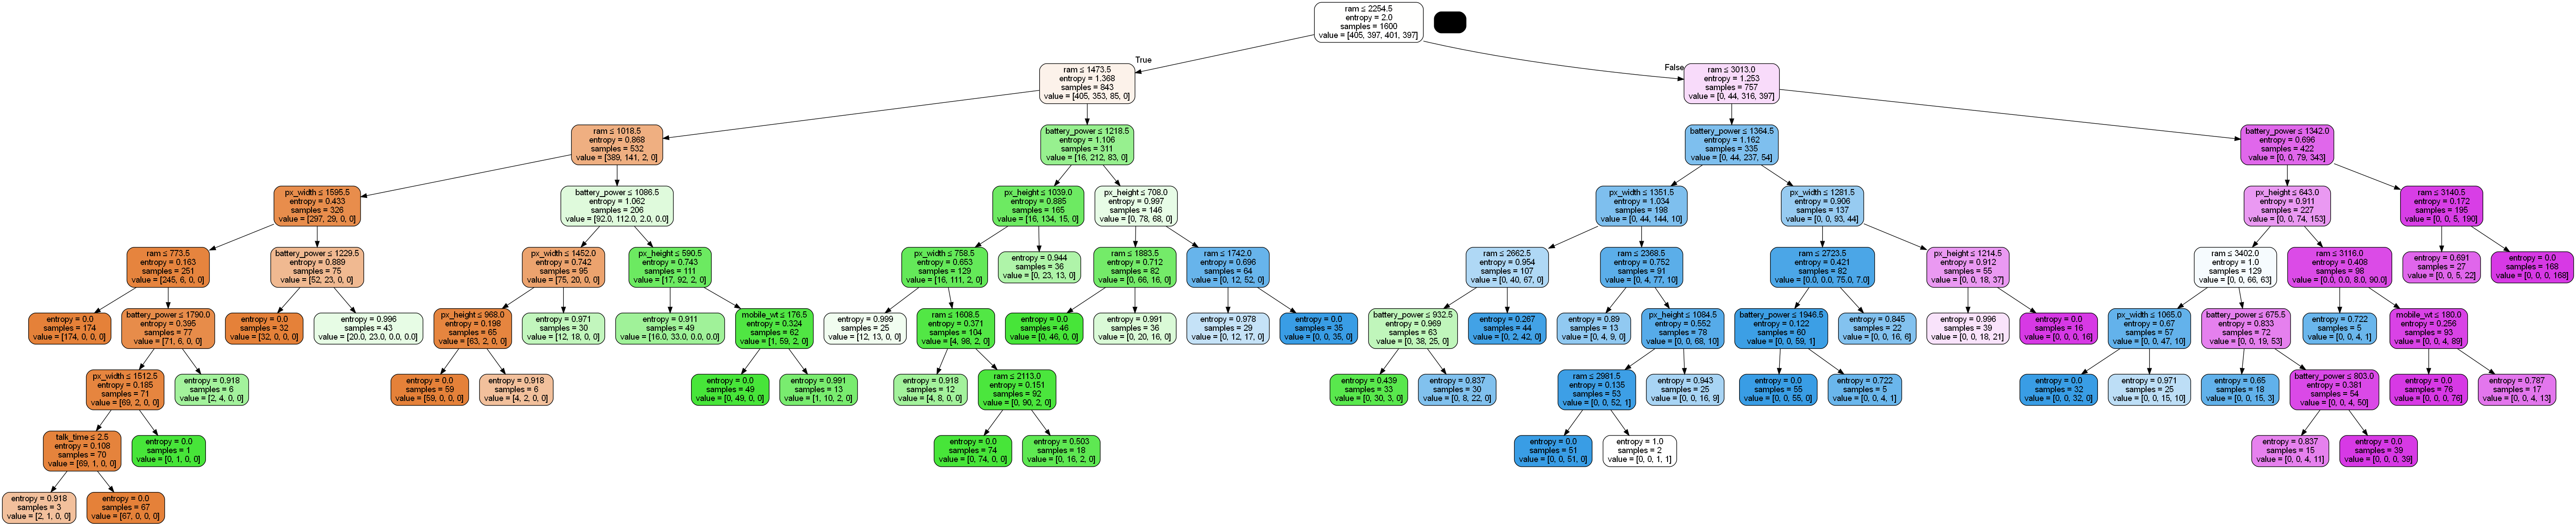

<Figure size 1200x1200 with 0 Axes>

In [ ]:
dot_data = StringIO()

import matplotlib.pyplot as plt
fig= plt.figure(figsize=(12,12))

export_graphviz(dt_mp  , out_file=dot_data,
                filled=True, rounded=True,
                special_characters=True , feature_names=mp_train_x.columns  )
graph = pydotplus.graph_from_dot_data(dot_data.getvalue())

(graph,) = pydot.graph_from_dot_data(dot_data.getvalue())
Image(graph.create_png())